# NASA C-MAPSS FD001 — BiLSTM RUL Prediction (No Attention)

This notebook follows the uploaded V3.1 BiLSTM pipeline, with the temporal attention module removed.

The BiLSTM reads each fixed-length sensor window in both directions. The final forward and backward hidden states are concatenated and passed to the regression head.

All preprocessing, engine-level validation, multiple validation cutoffs, target scaling, training controls, metrics, official test evaluation, and artifact saving follow the supplied V3.1 notebook.

## 1. Imports and reproducibility

In [1]:
import copy
import random
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline

import joblib
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = device.type == "cuda"

print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.13.0+cpu
Device: cpu


## 2. Configuration and dataset loading

Update `DATA_DIR` to the folder containing the three FD001 files. The notebook can be run in Colab or local Jupyter.

In [2]:
# Colab example:
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_DIR = Path("/content/drive/MyDrive/CMaps")

# Local Windows example — update this to your extracted C-MAPSS folder:
DATA_DIR = Path(r"D:\ML_project\extracted\CMaps")

SUBSET = "FD001"  # FD001, FD002, FD003, FD004

RUL_CAP = 125
WINDOW_SIZE = 30
VAL_SIZE = 0.20

# Evaluate only within the target range learned during training.
# Do not include 150/180 here when RUL_CAP is 125.
VALIDATION_RUL_POINTS = [20, 40, 60, 80, 100, 120, 125]

BATCH_SIZE = 128
HIDDEN_SIZE = 64
NUM_LAYERS = 1
DROPOUT = 0.30

LEARNING_RATE = 5e-4
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 100
PATIENCE = 15
GRAD_CLIP = 1.0

OUTPUT_DIR = Path("artifacts") / f"{SUBSET}_V3_1_improved"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

columns = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

read_options = {"sep": r"\s+", "header": None, "names": columns}

train_path = DATA_DIR / f"train_{SUBSET}.txt"
test_path = DATA_DIR / f"test_{SUBSET}.txt"
rul_path = DATA_DIR / f"RUL_{SUBSET}.txt"

for path in [train_path, test_path, rul_path]:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}. Update DATA_DIR/SUBSET.")

train_df = pd.read_csv(train_path, **read_options)
test_df = pd.read_csv(test_path, **read_options)
rul_df = pd.read_csv(rul_path, sep=r"\s+", header=None, names=["RUL"])

train_df = train_df.sort_values(["unit", "cycle"]).reset_index(drop=True)
test_df = test_df.sort_values(["unit", "cycle"]).reset_index(drop=True)

print("Train:", train_df.shape)
print("Test:", test_df.shape)
print("Official test RUL:", rul_df.shape)
display(train_df.head())


Train: (20631, 26)
Test: (13096, 26)
Official test RUL: (100, 1)


,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 3. Data checks and engine-level split

The split is performed on the list of unique engines. This makes the intent explicit: no engine can appear in both training and validation.

In [3]:
for name, frame in [("train", train_df), ("test", test_df)]:
    if frame[["unit", "cycle"]].isna().any().any():
        raise ValueError(f"Missing engine ID or cycle in {name} data.")
    if frame.duplicated(["unit", "cycle"]).any():
        raise ValueError(f"Duplicate (unit, cycle) rows in {name} data.")
    if not frame.groupby("unit")["cycle"].apply(lambda s: s.is_monotonic_increasing).all():
        raise ValueError(f"Cycles are not increasing within every {name} engine.")

engine_ids = train_df["unit"].unique()

splitter = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE, random_state=SEED)
train_engine_idx, val_engine_idx = next(
    splitter.split(engine_ids, groups=engine_ids)
)

train_units = np.sort(engine_ids[train_engine_idx])
val_units = np.sort(engine_ids[val_engine_idx])

train_part = train_df[train_df["unit"].isin(train_units)].copy()
val_part = train_df[train_df["unit"].isin(val_units)].copy()

print("Training engines:", len(train_units))
print("Validation engines:", len(val_units))
print("Engine overlap:", len(set(train_units) & set(val_units)))
assert len(set(train_units) & set(val_units)) == 0


Training engines: 80
Validation engines: 20
Engine overlap: 0


## 4. Construct training RUL labels and official test labels

Training labels are derived from each training engine's run-to-failure trajectory. The training target is capped at 125. The official test RUL file gives the number of cycles remaining after the last observed test cycle.

In [4]:
train_last_cycle = train_df.groupby("unit")["cycle"].max()

train_df["RUL_raw"] = (
    train_df["unit"].map(train_last_cycle) - train_df["cycle"]
).astype(np.float32)

train_df["RUL"] = train_df["RUL_raw"].clip(upper=RUL_CAP).astype(np.float32)

test_units = np.sort(test_df["unit"].unique())
test_final_rul = rul_df["RUL"].to_numpy(dtype=np.float32)

if len(test_units) != len(test_final_rul):
    raise ValueError("Test engine count does not match rows in the official RUL file.")

# NASA's supplied RUL file follows the test-engine ordering.
test_rul_map = dict(zip(test_units, test_final_rul))

print("Train raw RUL range:", train_df["RUL_raw"].min(), train_df["RUL_raw"].max())
print("Train capped RUL range:", train_df["RUL"].min(), train_df["RUL"].max())
print("Official test RUL range:", test_final_rul.min(), test_final_rul.max())

display(train_df[["unit", "cycle", "RUL_raw", "RUL"]].head())


# Refresh the split DataFrames now that the RUL target has been created.
# train_part/val_part created before this cell are copies and do not inherit
# columns added later to train_df.
train_part = train_df[train_df["unit"].isin(train_units)].copy()
val_part = train_df[train_df["unit"].isin(val_units)].copy()

assert "RUL" in train_part.columns
assert "RUL" in val_part.columns
assert set(train_part["unit"].unique()).isdisjoint(set(val_part["unit"].unique()))


Train raw RUL range: 0.0 361.0
Train capped RUL range: 0.0 125.0
Official test RUL range: 7.0 145.0


,unit,cycle,RUL_raw,RUL
0,1,1,191.0,125.0
1,1,2,190.0,125.0
2,1,3,189.0,125.0
3,1,4,188.0,125.0
4,1,5,187.0,125.0


## 5. Exploratory data analysis

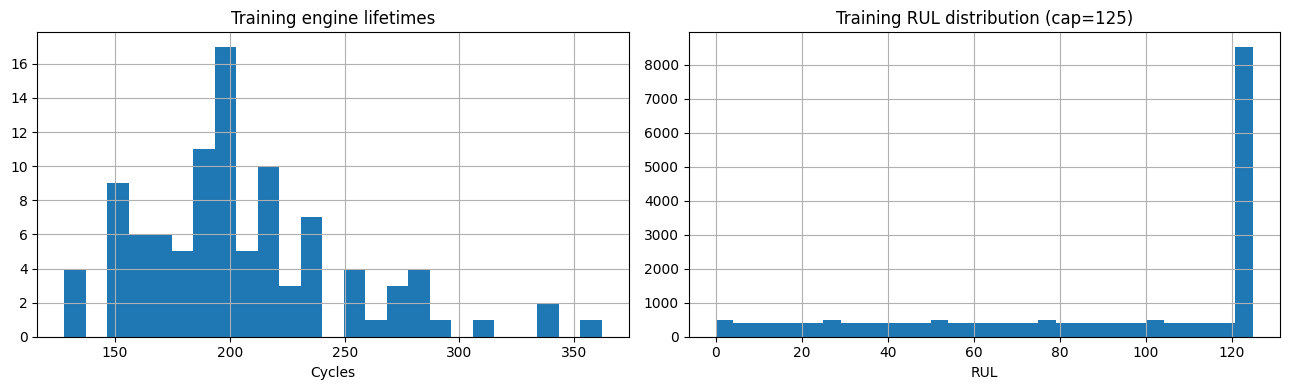

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

train_df.groupby("unit")["cycle"].max().hist(bins=25, ax=axes[0])
axes[0].set_title("Training engine lifetimes")
axes[0].set_xlabel("Cycles")

train_df["RUL"].hist(bins=30, ax=axes[1])
axes[1].set_title(f"Training RUL distribution (cap={RUL_CAP})")
axes[1].set_xlabel("RUL")

plt.tight_layout()
plt.show()


## 6. Feature selection — training engines only

The earlier V3 calculated feature variance on the complete training file before splitting engines. This is a small unsupervised leakage risk. Here, feature selection is fitted only on `train_part`.

Selected feature count: 18
Selected features: ['cycle', 'op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Removed constant/near-constant features: ['op_setting_3', 'sensor_1', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19', 'sensor_5']
Missing selected training values: 0


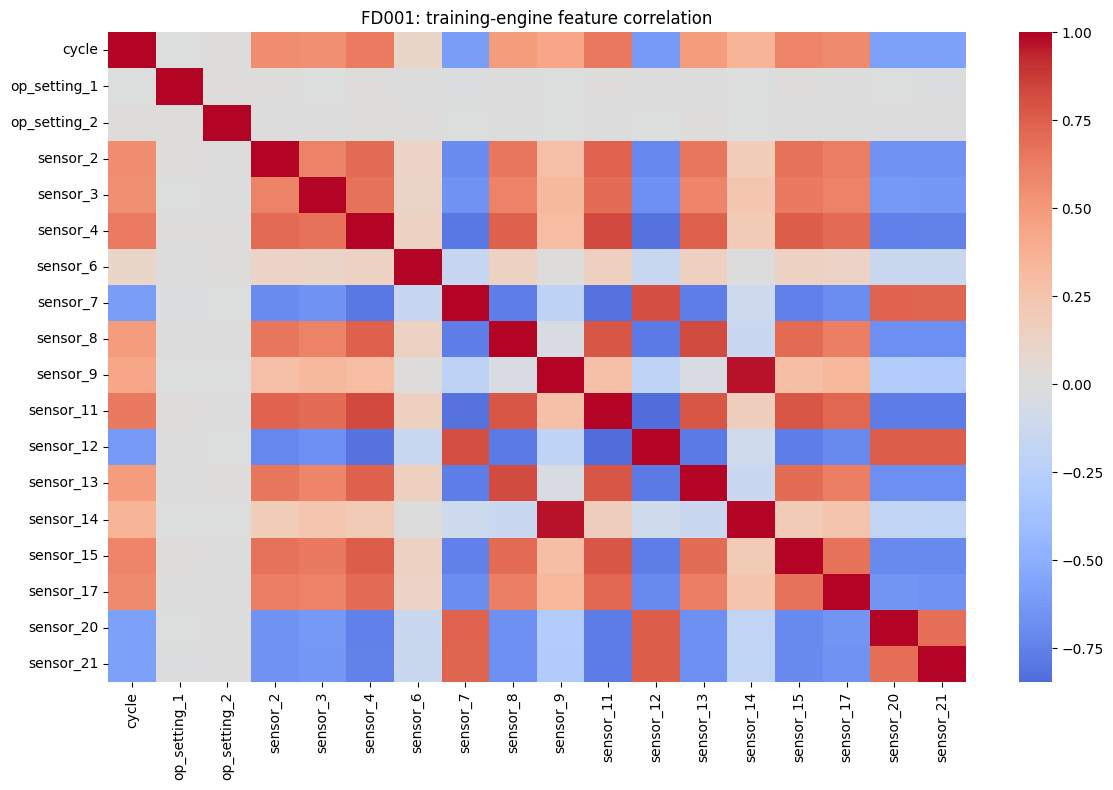

In [6]:
sensor_columns = [c for c in columns if c.startswith("sensor_")]
setting_columns = [c for c in columns if c.startswith("op_setting_")]

candidate_features = ["cycle"] + setting_columns + sensor_columns

feature_variance = train_part[candidate_features].var()
feature_columns = feature_variance[feature_variance > 1e-8].index.tolist()

removed_features = sorted(set(candidate_features) - set(feature_columns))

print("Selected feature count:", len(feature_columns))
print("Selected features:", feature_columns)
print("Removed constant/near-constant features:", removed_features)

missing_count = int(train_part[feature_columns].isna().sum().sum())
print("Missing selected training values:", missing_count)

plt.figure(figsize=(12, 8))
sns.heatmap(train_part[feature_columns].corr(), cmap="coolwarm", center=0)
plt.title(f"{SUBSET}: training-engine feature correlation")
plt.tight_layout()
plt.show()


## 7. Generate multiple validation cutoffs per engine

The previous V3 sampled one random cutoff per validation engine, and only from the later part of its lifetime. This version evaluates several RUL points per held-out engine. Each validation input still contains only observations available up to its cutoff.

In [7]:
val_records = []

for unit in val_units:
    engine = val_part[val_part["unit"] == unit].sort_values("cycle")
    final_cycle = int(engine["cycle"].max())

    for desired_rul in VALIDATION_RUL_POINTS:
        cutoff = final_cycle - int(desired_rul)
        prefix = engine[engine["cycle"] <= cutoff]

        # A valid sequence requires at least WINDOW_SIZE observed rows.
        if len(prefix) < WINDOW_SIZE:
            continue

        observed_cutoff = int(prefix["cycle"].iloc[-1])
        actual_rul = float(final_cycle - observed_cutoff)

        # Guard against any unexpected cycle gaps changing the label range.
        if actual_rul < 0:
            continue

        val_records.append({
            "unit": int(unit),
            "cutoff_cycle": observed_cutoff,
            "actual_rul": actual_rul,
            "target_rul": min(actual_rul, float(RUL_CAP))
        })

val_meta = pd.DataFrame(val_records)

if val_meta.empty:
    raise ValueError(
        "No valid validation cutoffs. Reduce WINDOW_SIZE or revise "
        "VALIDATION_RUL_POINTS."
    )

print("Validation samples:", len(val_meta))
print("Validation engines represented:", val_meta["unit"].nunique())
print("Validation actual RUL range:", val_meta["actual_rul"].min(),
      "to", val_meta["actual_rul"].max())
display(val_meta.head(10))


Validation samples: 137
Validation engines represented: 20
Validation actual RUL range: 20.0 to 125.0


,unit,cutoff_cycle,actual_rul,target_rul
0,1,172,20.0,20.0
1,1,152,40.0,40.0
2,1,132,60.0,60.0
3,1,112,80.0,80.0
4,1,92,100.0,100.0
5,1,72,120.0,120.0
6,1,67,125.0,125.0
7,5,249,20.0,20.0
8,5,229,40.0,40.0
9,5,209,60.0,60.0


## 8. Fit imputer and scaler on unique training rows

Overlapping sliding windows repeat the same cycle many times. Fitting the scaler on flattened windows implicitly weights interior cycles more heavily than edge cycles. Instead, fit preprocessing once on unique training rows, then transform all sequences.

In [8]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

imputer.fit(train_part[feature_columns])
train_imputed = imputer.transform(train_part[feature_columns])
scaler.fit(train_imputed)

def transform_features(frame, feature_columns, imputer, scaler):
    transformed = frame.copy()
    values = imputer.transform(transformed[feature_columns])
    values = scaler.transform(values).astype(np.float32)

    # Assign each scaled feature as a new float column. In particular, `cycle`
    # is originally integer-typed, while its standardized values are floats.
    for index, column in enumerate(feature_columns):
        transformed[column] = values[:, index]

    return transformed

train_scaled_df = transform_features(train_df, feature_columns, imputer, scaler)
test_scaled_df = transform_features(test_df, feature_columns, imputer, scaler)

print("Preprocessing fitted on unique training rows:", train_part.shape[0])


Preprocessing fitted on unique training rows: 16561


## 9. Build training and validation sequences

In [9]:
def make_training_windows(data, units, features, window_size):
    X, y = [], []

    for unit in units:
        engine = data[data["unit"] == unit].sort_values("cycle")
        values = engine[features].to_numpy(dtype=np.float32)
        targets = engine["RUL"].to_numpy(dtype=np.float32)

        for end in range(window_size - 1, len(engine)):
            X.append(values[end - window_size + 1:end + 1])
            y.append(targets[end])

    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)


def make_validation_windows(data, metadata, features, window_size):
    X, y, rows = [], [], []

    for record in metadata.itertuples(index=False):
        engine_prefix = data[
            (data["unit"] == record.unit) &
            (data["cycle"] <= record.cutoff_cycle)
        ].sort_values("cycle")

        values = engine_prefix[features].to_numpy(dtype=np.float32)

        if len(values) < window_size:
            continue

        X.append(values[-window_size:])
        actual_rul = float(record.actual_rul)
        y.append(actual_rul)
        rows.append({
            "unit": int(record.unit),
            "cutoff_cycle": int(record.cutoff_cycle),
            "actual_rul": actual_rul,
            "target_rul": min(actual_rul, float(RUL_CAP))
        })

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32),
        pd.DataFrame(rows)
    )


X_train, y_train = make_training_windows(
    train_scaled_df, train_units, feature_columns, WINDOW_SIZE
)

X_val, y_val_actual, val_meta_used = make_validation_windows(
    train_scaled_df, val_meta, feature_columns, WINDOW_SIZE
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("Validation labels:", y_val_actual.shape)


if len(X_train) == 0:
    raise ValueError("No training windows were generated. Check WINDOW_SIZE and engine lengths.")
if len(X_val) == 0:
    raise ValueError("No validation windows were generated. Check validation cutoffs.")
if not (len(X_val) == len(y_val_actual) == len(val_meta_used)):
    raise RuntimeError("Validation windows, labels, and metadata are misaligned.")


X_train: (14241, 30, 18)
y_train: (14241,)
X_val: (137, 30, 18)
Validation labels: (137,)


## 10. Scale regression targets

In [10]:
y_mean = float(y_train.mean())
y_std = float(y_train.std() + 1e-8)

y_train_scaled = (y_train - y_mean) / y_std

print("Target mean:", y_mean)
print("Target std:", y_std)


Target mean: 80.81237030029297
Target std: 41.8094596862793


## 11. Evaluation metrics

In [11]:
def nasa_score(actual, predicted):
    actual = np.asarray(actual, dtype=np.float64)
    predicted = np.asarray(predicted, dtype=np.float64)

    error = predicted - actual
    penalties = np.where(
        error < 0,
        np.exp(-error / 13.0) - 1.0,
        np.exp(error / 10.0) - 1.0
    )
    return float(np.sum(penalties))


def evaluate_rul(actual, predicted):
    actual = np.asarray(actual, dtype=np.float64)
    predicted = np.maximum(np.asarray(predicted, dtype=np.float64), 0.0)

    return {
        "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
        "MAE": float(mean_absolute_error(actual, predicted)),
        "NASA Score": nasa_score(actual, predicted),
        "Mean NASA Score": nasa_score(actual, predicted) / len(actual),
        "R2": float(r2_score(actual, predicted))
    }


## 12. Corrected classical baselines

**Important V3 flaw fixed here:** the old code selected the last row of every complete training engine. Since the training engines run to failure, every selected training row had RUL = 0. The models therefore learned a degenerate target. Here, RF/XGBoost train on all eligible training rows and are evaluated on the same held-out engine/cutoff rows as the BiLSTM.

In [12]:
# Training tabular baseline: all cycles from training engines.
X_tab_train = train_part[feature_columns]
y_tab_train = train_part["RUL"].to_numpy(dtype=np.float32)

# Validation tabular baseline: the observed row at each validation cutoff.
val_tab_rows = []
for record in val_meta_used.itertuples(index=False):
    row = val_part[
        (val_part["unit"] == record.unit) &
        (val_part["cycle"] == record.cutoff_cycle)
    ]
    if len(row) != 1:
        raise ValueError("Could not find exactly one row for a validation cutoff.")
    val_tab_rows.append(row.iloc[0])

val_tab_df = pd.DataFrame(val_tab_rows).reset_index(drop=True)
X_tab_val = val_tab_df[feature_columns]
y_tab_val_raw = val_meta_used["actual_rul"].to_numpy(dtype=np.float32)
y_tab_val_capped = np.minimum(y_tab_val_raw, RUL_CAP)

baseline_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=2,
        random_state=SEED,
        n_jobs=-1
    )
}

if XGBRegressor is not None:
    baseline_models["XGBoost"] = XGBRegressor(
        n_estimators=500,
        max_depth=5,
        learning_rate=0.03,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=2.0,
        objective="reg:squarederror",
        random_state=SEED,
        n_jobs=-1
    )

baseline_results = []
baseline_raw_results = []
baseline_fitted = {}

for name, estimator in baseline_models.items():
    pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        estimator
    )
    pipeline.fit(X_tab_train, y_tab_train)
    predictions = np.maximum(pipeline.predict(X_tab_val), 0.0)
    capped_predictions = np.clip(predictions, 0.0, RUL_CAP)

    # Primary comparison uses the capped target convention used for training.
    capped_scores = evaluate_rul(y_tab_val_capped, capped_predictions)
    raw_scores = evaluate_rul(y_tab_val_raw, predictions)

    baseline_results.append({"Model": name, **capped_scores})
    baseline_raw_results.append({"Model": name, **raw_scores})
    baseline_fitted[name] = pipeline

print("Baseline metrics on capped validation RUL (primary comparison):")
baseline_results_df = pd.DataFrame(baseline_results)
display(baseline_results_df.round(3))

print("Baseline metrics on uncapped validation RUL (supplementary):")
baseline_raw_results_df = pd.DataFrame(baseline_raw_results)
display(baseline_raw_results_df.round(3))


Baseline metrics on capped validation RUL (primary comparison):


,Model,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,Random Forest,18.757,14.486,968.146,7.067,0.740
1,XGBoost,19.062,14.509,1072.052,7.825,0.732


Baseline metrics on uncapped validation RUL (supplementary):


,Model,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,Random Forest,18.757,14.486,968.146,7.067,0.740
1,XGBoost,19.066,14.539,1072.609,7.829,0.732


## 13. BiLSTM architecture (without attention)

The encoder reads the sensor window in both directions. We concatenate the final forward and backward hidden states and pass this representation to the regression head. No attention scores or attention pooling are used.

In [13]:
class BiLSTMRegressor(nn.Module):
    def __init__(
        self,
        input_size,
        hidden_size=64,
        num_layers=1,
        dropout=0.30
    ):
        super().__init__()

        self.input_dropout = nn.Dropout(dropout * 0.5)

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        # Concatenate final forward and backward hidden states.
        representation_size = hidden_size * 2

        self.head = nn.Sequential(
            nn.LayerNorm(representation_size),
            nn.Linear(representation_size, 96),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(96, 32),
            nn.GELU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        # x: (batch, time_steps, input_features)
        x = self.input_dropout(x)
        _, (hidden, _) = self.lstm(x)

        # For a bidirectional LSTM:
        # hidden[-2] = final forward state; hidden[-1] = final backward state.
        final_state = torch.cat([hidden[-2], hidden[-1]], dim=1)

        return self.head(final_state).squeeze(1)


n_features = len(feature_columns)

model = BiLSTMRegressor(
    input_size=n_features,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(device)

num_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)
print(f"Trainable parameters: {num_parameters:,}")

BiLSTMRegressor(
  (input_dropout): Dropout(p=0.15, inplace=False)
  (lstm): LSTM(18, 64, batch_first=True, bidirectional=True)
  (head): Sequential(
    (0): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
    (1): Linear(in_features=128, out_features=96, bias=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=96, out_features=32, bias=True)
    (5): GELU(approximate='none')
    (6): Dropout(p=0.15, inplace=False)
    (7): Linear(in_features=32, out_features=1, bias=True)
  )
)
Trainable parameters: 58,785


## 14. Train the BiLSTM with early stopping

In [14]:
train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train_scaled, dtype=torch.float32)
)

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=PIN_MEMORY,
    num_workers=0,
    generator=loader_generator
)

val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
y_val_capped = np.minimum(y_val_actual, RUL_CAP)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=4
)

loss_fn = nn.SmoothL1Loss()

best_val_rmse = float("inf")
best_state = None
best_epoch = 0
epochs_without_improvement = 0
history = []

for epoch in range(1, MAX_EPOCHS + 1):
    lr_used = optimizer.param_groups[0]["lr"]

    model.train()
    running_loss = 0.0

    for batch_X, batch_y in train_loader:
        batch_X = batch_X.to(device, non_blocking=True)
        batch_y = batch_y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        predictions = model(batch_X)
        loss = loss_fn(predictions, batch_y)

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP)
        optimizer.step()

        running_loss += loss.item() * len(batch_X)

    train_loss = running_loss / len(train_dataset)

    model.eval()
    with torch.no_grad():
        val_scaled_predictions = model(val_tensor).cpu().numpy()

    val_predictions_raw = np.maximum(
        val_scaled_predictions * y_std + y_mean,
        0.0
    )
    val_predictions_capped = np.clip(val_predictions_raw, 0.0, RUL_CAP)

    # Checkpoint selection and LR scheduling must match the capped training target.
    val_rmse_capped = float(
        np.sqrt(mean_squared_error(y_val_capped, val_predictions_capped))
    )
    val_rmse_raw = float(
        np.sqrt(mean_squared_error(y_val_actual, val_predictions_raw))
    )

    scheduler.step(val_rmse_capped)
    next_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_rmse_capped": val_rmse_capped,
        "val_rmse_raw": val_rmse_raw,
        "lr_used": lr_used,
        "next_lr": next_lr
    })

    if val_rmse_capped < best_val_rmse:
        best_val_rmse = val_rmse_capped
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:03d}/{MAX_EPOCHS} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val RMSE capped: {val_rmse_capped:.3f} | "
            f"Val RMSE raw: {val_rmse_raw:.3f} | "
            f"LR used: {lr_used:.2e}"
        )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping. Best epoch: {best_epoch}")
        break

if best_state is None:
    raise RuntimeError("No valid model checkpoint was produced.")

model.load_state_dict(best_state)
model.eval()


Epoch 001/100 | Train loss: 0.1299 | Val RMSE capped: 81.307 | Val RMSE raw: 81.307 | LR used: 5.00e-04
Epoch 005/100 | Train loss: 0.0484 | Val RMSE capped: 82.773 | Val RMSE raw: 82.773 | LR used: 5.00e-04
Epoch 010/100 | Train loss: 0.0356 | Val RMSE capped: 80.690 | Val RMSE raw: 80.690 | LR used: 2.50e-04
Epoch 015/100 | Train loss: 0.0294 | Val RMSE capped: 82.012 | Val RMSE raw: 82.012 | LR used: 1.25e-04
Early stopping. Best epoch: 4


BiLSTMRegressor(
  (input_dropout): Dropout(p=0.15, inplace=False)
  (lstm): LSTM(18, 64, batch_first=True, bidirectional=True)
  (head): Sequential(
    (0): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
    (1): Linear(in_features=128, out_features=96, bias=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=96, out_features=32, bias=True)
    (5): GELU(approximate='none')
    (6): Dropout(p=0.15, inplace=False)
    (7): Linear(in_features=32, out_features=1, bias=True)
  )
)

## 15. Validation results and learning curves

The primary checkpoint-selection metric is RMSE on **capped RUL** because the network is trained on `min(RUL, 125)`. Raw-RUL metrics are shown only as supplementary diagnostics and should not be mixed with capped metrics when comparing models.

BiLSTM validation metrics (raw actual RUL; supplementary):


,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,77.741,68.415,277561.184,2025.994,-3.464


BiLSTM validation metrics (capped actual and capped predictions; primary):


,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,77.741,68.415,277561.184,2025.994,-3.464


Best epoch selected on capped validation RMSE: 4


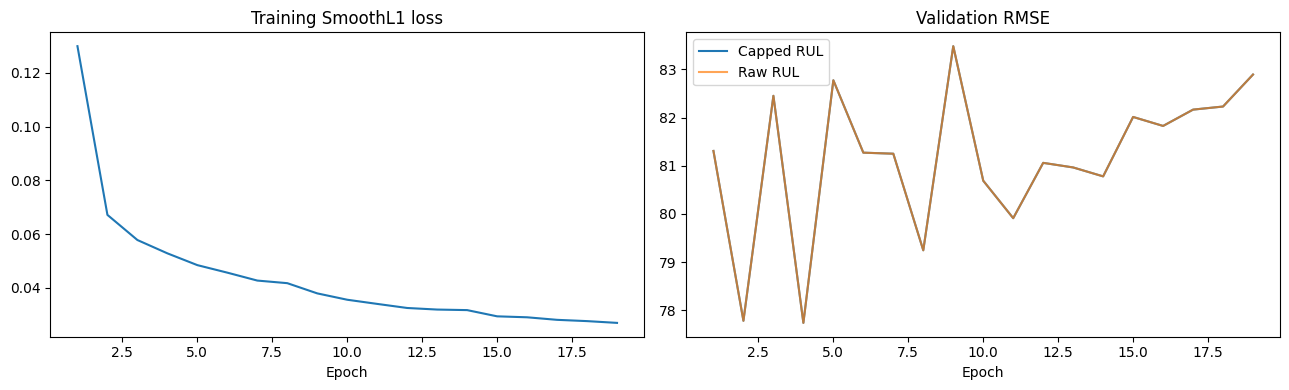

Model comparison on capped validation RUL (primary):


,Model,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,Random Forest,18.757,14.486,968.146,7.067,0.740
1,XGBoost,19.062,14.509,1072.052,7.825,0.732
2,BiLSTM + temporal attention,77.741,68.415,277561.184,2025.994,-3.464


Supplementary model comparison on raw validation RUL:


,Model,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,Random Forest,18.757,14.486,968.146,7.067,0.740
1,XGBoost,19.066,14.539,1072.609,7.829,0.732
2,BiLSTM + temporal attention,77.741,68.415,277561.184,2025.994,-3.464


In [15]:
with torch.no_grad():
    val_scaled_predictions = model(val_tensor).cpu().numpy()

val_predictions_unclipped = (
    val_scaled_predictions * y_std + y_mean
)
val_predictions = np.clip(val_predictions_unclipped, 0.0, RUL_CAP)

y_val_capped = np.minimum(y_val_actual, RUL_CAP)

val_scores_raw = evaluate_rul(y_val_actual, val_predictions)
val_capped_scores = evaluate_rul(y_val_capped, val_predictions)

print("BiLSTM validation metrics (raw actual RUL; supplementary):")
display(pd.DataFrame([val_scores_raw]).round(3))
print("BiLSTM validation metrics (capped actual and capped predictions; primary):")
display(pd.DataFrame([val_capped_scores]).round(3))
print("Best epoch selected on capped validation RMSE:", best_epoch)

history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"])
axes[0].set_title("Training SmoothL1 loss")
axes[0].set_xlabel("Epoch")

axes[1].plot(history_df["epoch"], history_df["val_rmse_capped"], label="Capped RUL")
axes[1].plot(history_df["epoch"], history_df["val_rmse_raw"], label="Raw RUL", alpha=0.7)
axes[1].set_title("Validation RMSE")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

# All models are ranked on the same capped validation targets.
comparison_rows = baseline_results + [{"Model": "BiLSTM + temporal attention", **val_capped_scores}]
validation_comparison = pd.DataFrame(comparison_rows).sort_values("RMSE")
print("Model comparison on capped validation RUL (primary):")
display(validation_comparison.round(3))

raw_comparison_rows = baseline_raw_results + [{"Model": "BiLSTM + temporal attention", **val_scores_raw}]
validation_raw_comparison = pd.DataFrame(raw_comparison_rows).sort_values("RMSE")
print("Supplementary model comparison on raw validation RUL:")
display(validation_raw_comparison.round(3))


## 16. Validation error analysis

,unit,cutoff_cycle,actual_rul,target_rul,predicted_RUL,error,absolute_error
124,81,115,125.0,125.0,5.152534,-119.847466,119.847466
76,45,33,125.0,125.0,5.631752,-119.368248,119.368248
69,40,63,125.0,125.0,5.767036,-119.232964,119.232964
131,84,142,125.0,125.0,5.902832,-119.097168,119.097168
13,5,144,125.0,125.0,6.345413,-118.654587,118.654587
97,71,83,125.0,125.0,6.579002,-118.420998,118.420998
55,32,66,125.0,125.0,6.945374,-118.054626,118.054626
41,23,43,125.0,125.0,7.449432,-117.550568,117.550568
62,34,70,125.0,125.0,7.512184,-117.487816,117.487816
20,11,115,125.0,125.0,7.865494,-117.134506,117.134506


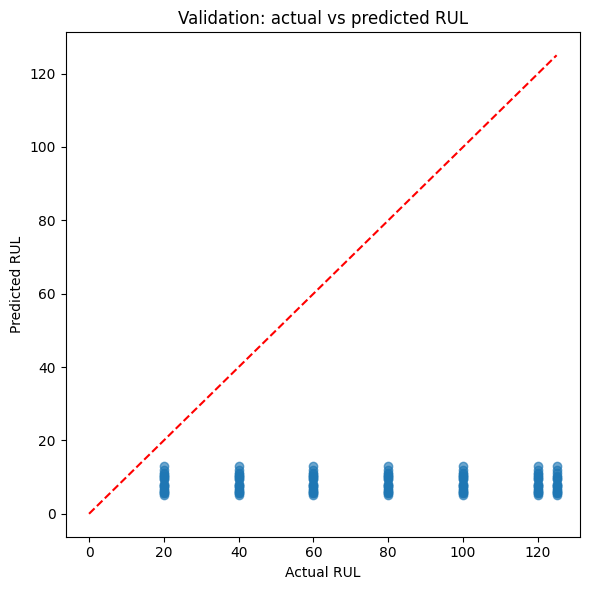

In [16]:
val_analysis = val_meta_used.copy()
val_analysis["predicted_RUL"] = val_predictions
val_analysis["error"] = val_analysis["predicted_RUL"] - val_analysis["actual_rul"]
val_analysis["absolute_error"] = val_analysis["error"].abs()

display(
    val_analysis.sort_values("absolute_error", ascending=False).head(20)
)

plt.figure(figsize=(6, 6))
plt.scatter(
    val_analysis["actual_rul"],
    val_analysis["predicted_RUL"],
    alpha=0.65
)
limit = max(
    val_analysis["actual_rul"].max(),
    val_analysis["predicted_RUL"].max()
)
plt.plot([0, limit], [0, limit], "r--")
plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Validation: actual vs predicted RUL")
plt.tight_layout()
plt.show()


## 17. Refit preprocessing and BiLSTM on all training engines

After model decisions are frozen using the held-out validation engines, refit the selected BiLSTM configuration on all official training engines. The number of epochs and learning-rate schedule come from the validation run.

In [17]:
# Refit preprocessing on all unique official training rows.
final_imputer = SimpleImputer(strategy="median")
final_scaler = StandardScaler()

final_imputer.fit(train_df[feature_columns])
train_all_imputed = final_imputer.transform(train_df[feature_columns])
final_scaler.fit(train_all_imputed)

train_all_scaled_df = transform_features(
    train_df, feature_columns, final_imputer, final_scaler
)
test_all_scaled_df = transform_features(
    test_df, feature_columns, final_imputer, final_scaler
)

X_full, y_full = make_training_windows(
    train_all_scaled_df,
    train_all_scaled_df["unit"].unique(),
    feature_columns,
    WINDOW_SIZE
)

# One final observed window per official test engine.
test_windows = []
for unit in test_units:
    engine = test_all_scaled_df[
        test_all_scaled_df["unit"] == unit
    ].sort_values("cycle")

    values = engine[feature_columns].to_numpy(dtype=np.float32)

    if len(values) < WINDOW_SIZE:
        raise ValueError(f"Test engine {unit} has fewer than WINDOW_SIZE rows.")

    test_windows.append(values[-WINDOW_SIZE:])

X_test = np.asarray(test_windows, dtype=np.float32)
y_test_actual = np.asarray(
    [test_rul_map[unit] for unit in test_units],
    dtype=np.float32
)

final_y_mean = float(y_full.mean())
final_y_std = float(y_full.std() + 1e-8)
y_full_scaled = (y_full - final_y_mean) / final_y_std

# Make the final refit reproducible and independent of the validation model's RNG history.
seed_everything(SEED + 1)

final_model = BiLSTMRegressor(
    input_size=len(feature_columns),
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(device)

final_dataset = TensorDataset(
    torch.tensor(X_full, dtype=torch.float32),
    torch.tensor(y_full_scaled, dtype=torch.float32)
)

final_generator = torch.Generator()
final_generator.manual_seed(SEED)

final_loader = DataLoader(
    final_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=PIN_MEMORY,
    num_workers=0,
    generator=final_generator
)

final_optimizer = torch.optim.AdamW(
    final_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

lr_schedule = [
    item["lr_used"] for item in history[:best_epoch]
]

for epoch in range(best_epoch):
    for group in final_optimizer.param_groups:
        group["lr"] = lr_schedule[epoch]

    final_model.train()

    for batch_X, batch_y in final_loader:
        batch_X = batch_X.to(device, non_blocking=True)
        batch_y = batch_y.to(device, non_blocking=True)

        final_optimizer.zero_grad(set_to_none=True)
        predictions = final_model(batch_X)
        loss = loss_fn(predictions, batch_y)
        loss.backward()

        nn.utils.clip_grad_norm_(
            final_model.parameters(),
            max_norm=GRAD_CLIP
        )

        final_optimizer.step()

final_model.eval()

print("Final training windows:", X_full.shape)
print("Official test windows:", X_test.shape)
print("Refit epochs:", best_epoch)


Final training windows: (17731, 30, 18)
Official test windows: (100, 30, 18)
Refit epochs: 4


## 18. Official test evaluation — run only after model decisions are frozen

In [18]:
test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
).to(device)

with torch.no_grad():
    test_scaled_predictions = final_model(test_tensor).cpu().numpy()

test_predictions_unclipped = np.maximum(
    test_scaled_predictions * final_y_std + final_y_mean,
    0.0
)
# Training labels are capped at RUL_CAP, so the deployed prediction is capped too.
test_predictions = np.clip(test_predictions_unclipped, 0.0, RUL_CAP)
test_actual_capped = np.minimum(y_test_actual, RUL_CAP)

test_scores = evaluate_rul(y_test_actual, test_predictions)
test_capped_scores = evaluate_rul(test_actual_capped, test_predictions)

print("Official test metrics against raw supplied RUL:")
display(pd.DataFrame([test_scores]).round(3))
print("Official test metrics against capped supplied RUL:")
display(pd.DataFrame([test_capped_scores]).round(3))


Official test metrics against raw supplied RUL:


,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,14.572,10.337,350.688,3.507,0.877


Official test metrics against capped supplied RUL:


,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,13.296,9.267,314.362,3.144,0.89


## 19. Official test error analysis

,unit,actual_RUL,predicted_RUL,error,absolute_error
44,45,114.0,64.351685,-49.648315,49.648315
66,67,77.0,116.232559,39.232559,39.232559
78,79,63.0,101.595207,38.595207,38.595207
72,73,131.0,96.771889,-34.228111,34.228111
92,93,85.0,50.908821,-34.091179,34.091179
54,55,137.0,104.813797,-32.186203,32.186203
88,89,136.0,105.984695,-30.015305,30.015305
14,15,83.0,110.715752,27.715752,27.715752
1,2,98.0,124.155228,26.155228,26.155228
94,95,128.0,102.163773,-25.836227,25.836227


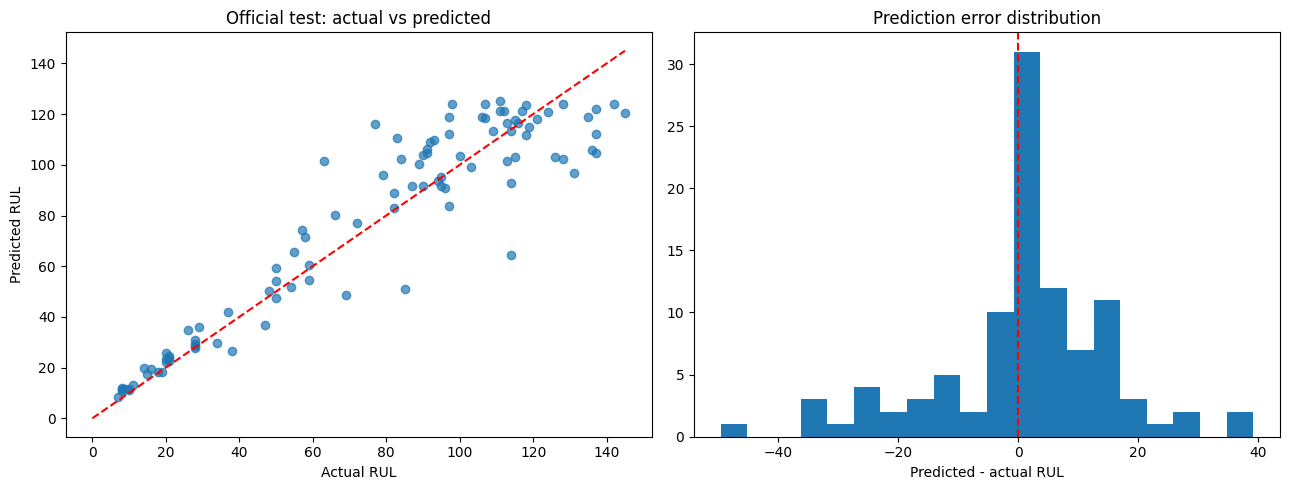

In [19]:
test_results = pd.DataFrame({
    "unit": test_units,
    "actual_RUL": y_test_actual,
    "predicted_RUL": test_predictions
})

test_results["error"] = (
    test_results["predicted_RUL"] - test_results["actual_RUL"]
)
test_results["absolute_error"] = test_results["error"].abs()

display(
    test_results.sort_values("absolute_error", ascending=False).head(20)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    test_results["actual_RUL"],
    test_results["predicted_RUL"],
    alpha=0.7
)
limit = max(
    test_results["actual_RUL"].max(),
    test_results["predicted_RUL"].max()
)
axes[0].plot([0, limit], [0, limit], "r--")
axes[0].set_xlabel("Actual RUL")
axes[0].set_ylabel("Predicted RUL")
axes[0].set_title("Official test: actual vs predicted")

axes[1].hist(test_results["error"], bins=20)
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted - actual RUL")
axes[1].set_title("Prediction error distribution")

plt.tight_layout()
plt.show()


## 20. Save model and preprocessing artifacts

In [20]:
checkpoint_path = OUTPUT_DIR / "bilstm_cmapss_no_attention.pt"
preprocess_path = OUTPUT_DIR / "bilstm_preprocessing.joblib"
metadata_path = OUTPUT_DIR / "bilstm_metadata.json"
results_path = OUTPUT_DIR / "bilstm_test_predictions.csv"

torch.save({
    "model_state_dict": final_model.state_dict(),
    "input_size": len(feature_columns),
    "hidden_size": HIDDEN_SIZE,
    "num_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "window_size": WINDOW_SIZE,
    "feature_columns": feature_columns,
    "rul_cap": RUL_CAP,
    "subset": SUBSET
}, checkpoint_path)

joblib.dump({
    "imputer": final_imputer,
    "scaler": final_scaler,
    "target_mean": final_y_mean,
    "target_std": final_y_std,
    "feature_columns": feature_columns
}, preprocess_path)

with open(metadata_path, "w") as file:
    json.dump({
        "subset": SUBSET,
        "window_size": WINDOW_SIZE,
        "rul_cap": RUL_CAP,
        "best_validation_epoch": best_epoch,
        "validation_metrics_raw_rul": val_scores_raw,
        "validation_metrics_capped_rul": val_capped_scores,
        "official_test_metrics_raw_rul": test_scores,
        "official_test_metrics_capped_rul": test_capped_scores,
        "num_parameters": num_parameters,
        "model": "BiLSTM without attention",
        "validation_cutoff_rul_points": VALIDATION_RUL_POINTS,
        "target_cap": RUL_CAP
    }, file, indent=2)

test_results.to_csv(results_path, index=False)

print("Saved artifacts:")
print(checkpoint_path)
print(preprocess_path)
print(metadata_path)
print(results_path)


Saved artifacts:
artifacts\FD001_V3_1_improved\bilstm_cmapss_no_attention.pt
artifacts\FD001_V3_1_improved\bilstm_preprocessing.joblib
artifacts\FD001_V3_1_improved\bilstm_metadata.json
artifacts\FD001_V3_1_improved\bilstm_test_predictions.csv


## 21. What this V3.1 does and does not claim

### Fixed or improved
- Validation points stay inside the target's supported range (RUL 20–125).
- Training and validation use the same capped-RUL convention.
- The uploaded notebook's model-class mismatch is removed: the same `BiLSTMRegressor` is instantiated in validation and final refitting.
- The model is smaller than the original 2-layer, 96-unit BiLSTM to reduce overfitting.
- Temporal attention pooling lets the network learn a weighted summary of all encoded time steps.
- Validation and tabular baselines use the same held-out engines and cutoff samples.
- Preprocessing is fitted on unique training rows, not repeated overlapping windows.

### Important limitations
- This notebook has not been run against your local dataset in this session. No new RMSE can honestly be claimed yet.
- Attention weights are model weights over encoded time steps; they do not prove that a particular sensor event caused a failure.
- Compare BiLSTM against Random Forest/XGBoost on the same capped validation metric. A more complex network is not automatically better.
- For a robust report, repeat the experiment with several seeds and report mean ± standard deviation.

Run every cell from top to bottom after setting `DATA_DIR`. Do not mix old output cells with this source code.
